# 16-385 Computer Vision test

## Programming Assignment 2: Augmented Reality with Planar Homographies

In this assignment, you will be implementing a panorama application step by step using planar
homographies. Before we step into the implementation, we will walk you through the theory of planar
homographies. In the programming section, you will first learn to find point correspondences between
two images and use these to estimate the homography between them. Using this homography, you will
then warp images and finally implement your own panorama application.

---
## Instructions

1. **Integrity and collaboration:** Students are encouraged to work in groups but each student must submit their own work. If you work as a group, include the names of your collaborators in your write up. Code should NOT be shared or copied. Please DO NOT use external code unless permitted. Plagiarism is strongly prohibited and may lead to failure of this course.

2. **Start early!** Especially those not familiar with Python.

3. **Questions:** If you have any questions, please look at Piazza first. Other students may have encountered the same problem, and it may be solved already. If not, post your question on the discussion board. Teaching staff will respond as soon as possible.

4. **File paths:** Excluding the assignment setup, please make sure that any file paths that you use are relative and not absolute. Not `cv2.imread('/content/drive/MyDrive/hw1/data/xyz.jpg')` but `cv2.imread('./data/xyz.jpg')`.

5. **Submission:** Handing in your assignments involves **two** separate submissions via Gradescope: one for your code + results, and one for a pdf version of your code showing any requested results. The submission time will be the later of the two timestamps associated with these submissions. For example, if you submit your full solution before the deadline and submit your write-up 1 day late, your assignment will be considered 1 day late. Once submitted, **double check that the pdf can be viewed from within Gradescope and that you submitted the correct files!!**


### Assignment Setup
Run the next cell to use the bundled files. Local Jupyter uses this repository; Google Colab clones it without requiring Google Drive access.


In [ ]:
from pathlib import Path
import os
import subprocess
import sys

# Find the complete bundle when launched from the repository or an assignment folder.
REPO_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                  if (p / "requirements.txt").is_file()
                  and all((p / f"hw{i}").is_dir() for i in range(4))), None)
if REPO_ROOT is None and Path("/content").is_dir():
    try:
        import google.colab
    except ImportError:
        pass
    else:
        REPO_ROOT = Path("/content/CMU-16-385-Computer-Vision")
        if not REPO_ROOT.exists():
            subprocess.run(["git", "clone", "--depth", "1",
                            "https://github.com/pedier/CMU-16-385-Computer-Vision.git",
                            str(REPO_ROOT)], check=True)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r",
                        str(REPO_ROOT / "requirements.txt")], check=True)
if REPO_ROOT is None:
    raise FileNotFoundError("Clone the complete repository and launch Jupyter from it.")
os.chdir(REPO_ROOT / "hw2")
Path("results").mkdir(exist_ok=True)
print("Working directory:", Path.cwd())


In [ ]:
# All assignment assets are already included in this repository.
DATA_DIR = "data"
RES_DIR = "results"
ROT_MATCHES_PATH = os.path.join(RES_DIR, "brief_rot_test.pkl")


Now run the following code to import the modules you'll need.

In [3]:
import os
import numpy as np
import cv2
import skimage.color
import pickle
from matplotlib import pyplot as plt
import scipy
from skimage.util import montage
import time

PATCHWIDTH = 9

def read_pickle(path):
    with open(path, "rb") as f:
        return pickle.load(f)

def write_pickle(path, data):
    with open(path, "wb") as f:
        pickle.dump(data, f)

def briefMatch(desc1,desc2,ratio):

    matches = skimage.feature.match_descriptors(desc1,desc2,
                                                'hamming',
                                                cross_check=True,
                                                max_ratio=ratio)
    return matches

def plotMatches(img1,img2,matches,locs1,locs2):

    fig, ax = plt.subplots(nrows=1, ncols=1)
    img1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
    img2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)
    plt.axis('off')
    skimage.feature.plot_matched_features(img1,img2,
                                          keypoints0=locs1,keypoints1=locs2,
                                          matches=matches,ax=ax,
                                          matches_color='r',only_matches=True)
    plt.show()
    return

def makeTestPattern(patchWidth, nbits):

    np.random.seed(0)
    compareX = patchWidth*patchWidth * np.random.random((nbits,1))
    compareX = np.floor(compareX).astype(int)
    np.random.seed(1)
    compareY = patchWidth*patchWidth * np.random.random((nbits,1))
    compareY = np.floor(compareY).astype(int)

    return (compareX, compareY)

def computePixel(img, idx1, idx2, width, center):

    # BRIEF indices contain one value; extract scalars for current NumPy.
    idx1 = int(np.asarray(idx1).item())
    idx2 = int(np.asarray(idx2).item())

    halfWidth = width // 2
    col1 = idx1 % width - halfWidth
    row1 = idx1 // width - halfWidth
    col2 = idx2 % width - halfWidth
    row2 = idx2 // width - halfWidth
    return 1 if img[int(center[0]+row1)][int(center[1]+col1)] < img[int(center[0]+row2)][int(center[1]+col2)] else 0

def computeBrief(img, locs):

    patchWidth = 9
    nbits = 256
    compareX, compareY = makeTestPattern(patchWidth,nbits)
    m, n = img.shape

    halfWidth = patchWidth//2

    locs = np.array(list(filter(lambda x: halfWidth <= x[0] < m-halfWidth and halfWidth <= x[1] < n-halfWidth, locs)))
    desc = np.array([list(map(lambda x: computePixel(img, x[0], x[1], patchWidth, c), zip(compareX, compareY))) for c in locs])

    return desc, locs

def corner_detection(img, sigma):

    # fast method
    result_img = skimage.feature.corner_fast(img, n=PATCHWIDTH, threshold=sigma)
    locs = skimage.feature.corner_peaks(result_img, min_distance=1)
    return locs


---
## Section 1: Computing Planar Homographies

### 1.1 Feature Detection and Matching

Before finding the homography between an image pair, we need to find corresponding point pairs between two images. But how do we get these points? One way is to select them manually, which is tedious and inefficient. The CV way is to find interest points in the image pair and automatically match them. In the interest of being able to do cool stuff, you will not reimplement a feature detector or descriptor here by yourself. The logic for these can be found in the code above.

The purpose of an interest point detector (e.g., Harris) is to find particular salient points in the images
around which we extract feature descriptors (e.g., SIFT). These descriptors try to summarize the content of the image around the feature points in as succint yet descriptive manner possible (there is often a trade-off between representational and computational complexity for many computer vision tasks; you can have a very high dimensional feature descriptor that would ensure that you get good matches, but computing it could be prohibitively expensive).

Matching, then, is a task of trying to find a descriptor in the list of descriptors obtained after computing them on a new image that best matches the current descriptor. This could be something as simple as the Euclidean distance between the two descriptors, or something more complicated, depending on how the descriptor is composed. For the purpose of this exercise, we shall use the widely used FAST detector in concert with the BRIEF descriptor.

#### 1.1.1 FAST Detector (5 points)

How is the FAST detector different from the Harris corner detector that you've seen in the lectures? Can you comment on its computation performance compared to the Harris corner detector? You can reference the original paper [here](https://arxiv.org/pdf/0810.2434) and OpenCV tutorial [here](https://docs.opencv.org/3.0-beta/doc/py_tutorials/py_feature2d/py_fast/py_fast.html).

We know that Harris corner detector uses image gradient by constructing a structure tensor M and computing a corner response, using its determinant and trace. This essentially measures its eigenvalues. Both of them have to be large to indicate a strong corner, which has substantial variation in intensity in both directions, while a large value in just one direction could indicate an edge. In contrast, FAST simply examines a circle of 16 pixels around a candidate pixel p with intensity I(p). It detects p as a corner if there are n contiguous pixels in the circle which are all brighter than I(p) + t, or all darker than I(p) - t, where t is a predefined threshold.

FAST is much faster than Harris. The main reason I would propose is that it avoids computing gradients and matrix-based responses completely. The comparisons are cheap, and rejection can happen very early after only a few checks.

#### 1.1.2 BRIEF Descriptor (5 points)

How is the BRIEF descriptor different from the filterbanks you've seen in the lectures? Could you use any one of the those filter banks as a descriptor? You can reference the original paper [here](https://www.cs.ubc.ca/~lowe/525/papers/calonder_eccv10.pdf).

BRIEF describes a patch by comparing intensity at predetermined pairs of locations, and concatenating the results into a binary string. The corresponding bits are comparable because the same set of "questions" are being asked. In contrast, filterbanks we've seen in the lectures, such as Gabor filters, produce numerical responses.

Yes, filterbanks could serve as descriptors. We could apply a Gabor filterbank around every point of interest and pool the responses over spatial cells. Then we concatenate them into a vector, as how we construct GIST. Notice that such descriptors should typically require more computation and storage than BRIEF.

#### 1.1.3 Matching Methods (5 points)

Describe how the Hamming distance and Nearest Neighbor can be used to match interest points with BRIEF descriptors. What benefits does the Hamming distance have over a more conventional Euclidean distance measure in our setting?

Consider two BRIEF descriptors. The Hamming distance simply counts the positions where their bits differ. Nearest Neighbor pairs each descriptor in the first image with the descriptor in the second image that gives the smallest Hamming distance, which indicates the highest similarity. Compared to Euclidean distance, Hamming distance is extremely efficient for our binary descriptors. It is computationally cheap to use, mostly, bitwise operation.

#### 1.1.4 Feature Matching (10 points)

Please implement this feature matching function:
```
matches, locs1, locs2 = matchPics(I1, I2, ratio, sigma)
```
where `I1` and `I2` are the images you want to match, `ratio` is the ratio for the BRIEF feature descriptor, and `sigma` is threshold for corner detection using FAST feature detector. `locs1` and `locs2` are N x 2 matrices containing the x and y coordinates of the matched point pairs. `matches` is a p x 2 matrix where the first column is indices into descriptor of features in `I1` and similarly second column contains indices related to `I2`. Use the provided helper function `corner_detection()` to compute the features, then build descriptors using `computeBrief()`, and finally compare them using `briefMatch()`.
```
locs = corner_detection(img, sigma)
desc, locs = computeBrief(img, locs)
matches = briefMatch(desc1, desc2, ratio)
```
`locs` is an N x 2 matrix in which each row represents the location (x, y) of a feature point. Please note that the number of valid output feature points could be less than the number of input feature points. `desc` is the corresponding matrix of BRIEF descriptors for the interest points.

In [7]:
def matchPics(I1, I2, ratio, sigma):
    """
    Match features across images

    Input
    -----
    I1, I2: Source images (RGB or Grayscale uint8)
    ratio: ratio for BRIEF feature descriptor
    sigma: threshold for corner detection using FAST feature detector

    Returns
    -------
    matches: List of indices of matched features across I1, I2 [p x 2]
    locs1, locs2: Pixel coordinates of matches [N x 2]
    """

    # ===== your code here! =====

    # convert to greyscale
    def to_grayscale(img):
      normalized = img.astype(np.float64) / 255.0
      # RGB has .ndim == 3
      return normalized if img.ndim != 3 else skimage.color.rgb2gray(normalized)

    grayscale1 = to_grayscale(I1)
    grayscale2 = to_grayscale(I2)

    # TODO: Detect features in both images
    locs1 = corner_detection(grayscale1, sigma)
    locs2 = corner_detection(grayscale2, sigma)

    # TODO: Obtain descriptors for the computed feature locations
    desc1, locs1 = computeBrief(grayscale1, locs1)
    desc2, locs2 = computeBrief(grayscale2, locs2)

    # TODO: Match features using the descriptors
    locs1 = np.asarray(locs1).reshape(-1, 2)
    locs2 = np.asarray(locs2).reshape(-1, 2)
    if len(desc1) == 0 or len(desc2) == 0:
      matches = np.empty((0, 2), dtype=int)
    else:
      matches = briefMatch(desc1, desc2, ratio)

    # ==== end of code ====

    return matches, locs1, locs2

![Figure 1](http://16385.courses.cs.cmu.edu/fall2026/assets/assignments/hw2/fig1.png)
*Figure 1:* A few matched FAST feature points with the BRIEF descriptor.

Now implement the function `displayMatched()` using `matchPics()` and the provided function
`plotMatches()`. Call `displayMatched()` to visualize your matched points and include the result in
your report. The number of matches between the images may vary based on the `ratio` and `sigma` values. You can vary these to get the best results. The example shown in Figure 1 is with `ratio = 0.7` and `sigma = 0.15`.

In [8]:
def displayMatched(I1, I2, ratio, sigma):
    """
    Displays matches between two images

    Input
    -----
    I1, I2: Source images
    ratio: ratio for BRIEF feature descriptor
    sigma: threshold for corner detection using FAST feature detector
    """

    print('Displaying matches for ratio: ', ratio, ' and sigma: ', sigma)

    # ===== your code here! =====
    matches, locs1, locs2 = matchPics(I1, I2, ratio, sigma)
    plotMatches(I1, I2, matches, locs1, locs2)

    # ==== end of code ====


Use the cell below to visualize the matches. The resulting figure should look similar (but not necessarily identical) to Figure 1. Feel free to play around with the images and parameters. Please use the original images when submitting the report.

Figure 1 parameters:
*   image1_name = "cv_cover.jpg"
*   image2_name = "cv_desk.png"
*   ratio = 0.7
*   sigma = 0.15

Displaying matches for ratio:  0.7  and sigma:  0.15


/tmp/ipykernel_1104/3128789144.py:60: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  return 1 if img[int(center[0]+row1)][int(center[1]+col1)] < img[int(center[0]+row2)][int(center[1]+col2)] else 0


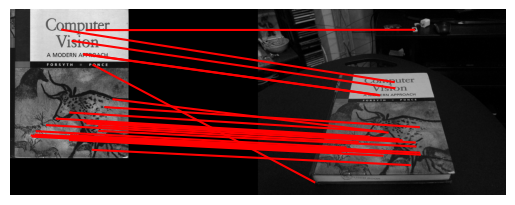

In [11]:
# Feel free to play around with these parameters
# BUT when submitting the report use the original images
image1_name = "cv_cover.jpg"
image2_name = "cv_desk.png"
ratio = 0.7
sigma = 0.15

image1_path = os.path.join(DATA_DIR, image1_name)
image2_path = os.path.join(DATA_DIR, image2_name)

image1 = cv2.imread(image1_path)
image2 = cv2.imread(image2_path)

#bgr to rgb
if len(image1.shape) == 3 and image1.shape[2] == 3:
  image1 = cv2.cvtColor(image1, cv2.COLOR_BGR2RGB)

if len(image2.shape) == 3 and image2.shape[2] == 3:
  image2 = cv2.cvtColor(image2, cv2.COLOR_BGR2RGB)

displayMatched(image1, image2, ratio, sigma)

#### 1.1.5 Experiment with `sigma` and `ratio` (10 points)

Conduct a small sensitivity analysis by calling `displayMatched` with various `sigma` and `ratio` values.
Include the figures displaying the matched features with various parameters in your writeup, and
explain the effect of these two parameters respectively.



Displaying matches for ratio:  0.7  and sigma:  0.05


/tmp/ipykernel_1104/3128789144.py:60: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  return 1 if img[int(center[0]+row1)][int(center[1]+col1)] < img[int(center[0]+row2)][int(center[1]+col2)] else 0


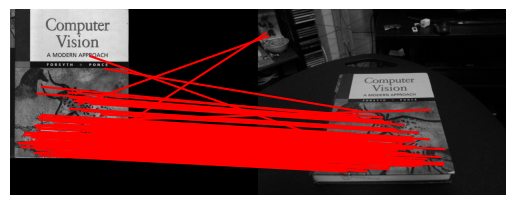



Displaying matches for ratio:  0.7  and sigma:  0.15


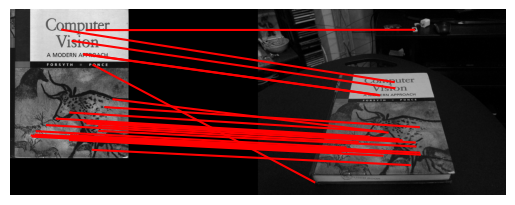



Displaying matches for ratio:  0.7  and sigma:  0.35


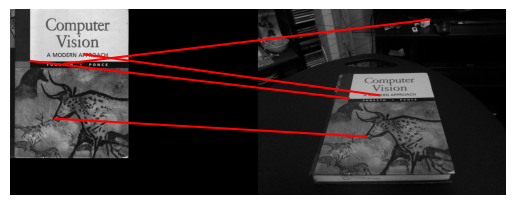







Displaying matches for ratio:  0.5  and sigma:  0.15


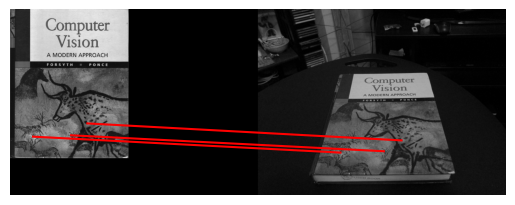



Displaying matches for ratio:  0.7  and sigma:  0.15


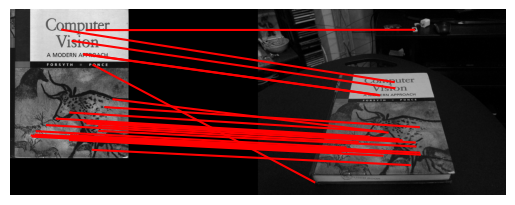



Displaying matches for ratio:  0.9  and sigma:  0.15


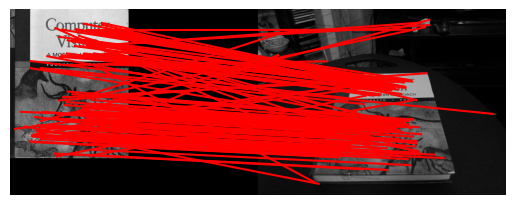

In [14]:
image1_name = "cv_cover.jpg"
image2_name = "cv_desk.png"

image1_path = os.path.join(DATA_DIR, image1_name)
image2_path = os.path.join(DATA_DIR, image2_name)

image1 = cv2.imread(image1_path)
image2 = cv2.imread(image2_path)

#bgr to rgb
if len(image1.shape) == 3 and image1.shape[2] == 3:
  image1 = cv2.cvtColor(image1, cv2.COLOR_BGR2RGB)

if len(image2.shape) == 3 and image2.shape[2] == 3:
  image2 = cv2.cvtColor(image2, cv2.COLOR_BGR2RGB)

# ===== your code here! =====
for sigma in [0.05, 0.15, 0.35]:
  print("\n")
  displayMatched(image1, image2, ratio=0.7, sigma=sigma)

print("\n\n\n")

for ratio in [0.5, 0.7, 0.9]:
  print("\n")
  displayMatched(image1, image2, ratio=ratio, sigma=0.15)

# ==== end of code ====

Effect of sigma: We observe that as we increase sigma from 0.05 to 0.35, the number of matches displayed ***decreases*** significantly. A higher threshold imposes lower tolerance on weaker intensity variations to qualify as corners. Even when sigma = 0.35, we still see an incorrect match. Thus, increasing the threshold does leave fewer candidate features but could still retain inaccuracy.

Effect of ratio: We observe that as we increase ratio from 0.5 to 0.9, the number of matches displayed ***increases*** significantly. At low ratio, few matches could survive because the best match had to be substantially better than the second best. As we elevate the ratio and are less strict, it becomes easier for more matches to be accepted. But this includes more obvious incorrect mismatches.

#### 1.1.6 BRIEF and Rotations (10 points)

Let’s investigate how BRIEF works with rotations. Implement the function
```
briefRot(min_deg, max_deg, deg_inc, ratio, sigma, filename)
```
that:
* Takes the cv cover.jpg and matches it to itself rotated from 0 to 360 degrees in increments of 10 degrees. [Hint: use `scipy.ndimage.rotate`]
* Stores the degrees of rotation and the number of matches at each degree which will be later used to plot a histogram.
* Visualizes the feature matching results at least three different orientations.

In [16]:
def briefRot(min_deg, max_deg, deg_inc, ratio, sigma, filename):
    """
    Tests Brief with rotations.

    Input
    -----
    min_deg: minimum degree to rotate image
    max_deg: maximum degree to rotate image
    deg_inc: number of degrees to increment when iterating
    ratio: ratio for BRIEF feature descriptor
    sigma: threshold for corner detection using FAST feature detector
    filename: filename of image to rotate

    """

    if not os.path.exists(RES_DIR):
      raise RuntimeError('RES_DIR does not exist. did you run all cells?')

    # Read the image and convert bgr to rgb
    image_path = os.path.join(DATA_DIR, filename)
    image = cv2.imread(image_path)
    if len(image.shape) == 3 and image.shape[2] == 3:
      image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    match_degrees = [] # stores the degrees of rotation
    match_counts = [] # stores the number of matches at each degree of rotation

    for i in range(min_deg, max_deg, deg_inc):
        print(i)

        # ===== your code here! =====
        # Rotate Image
        rotated = scipy.ndimage.rotate(image, i, reshape=True)

        # Match features in images
        matches, locs1, locs2 = matchPics(image, rotated, ratio, sigma)

        # Visualizes matches at at least 3 different orientations
        # to include in your report
        if i in [0, 30, 90]:
          plotMatches(image, rotated, matches, locs1, locs2)

        # Update match_degrees and match_counts
        match_degrees.append(i)
        match_counts.append(len(matches))

        # ==== end of code ====

    # Save to pickle file
    matches_to_save = [match_counts, match_degrees, deg_inc]
    write_pickle(ROT_MATCHES_PATH, matches_to_save)

def dispBriefRotHist(matches_path=ROT_MATCHES_PATH):
    # Check if pickle file exists
    if not os.path.exists(matches_path):
      raise RuntimeError('matches_path does not exist. did you call briefRot?')

    # Read from pickle file
    match_counts, match_degrees, deg_inc = read_pickle(matches_path)

    # Display histogram
    # Bins are centered and separated every 10 degrees
    plt.figure()
    bins = [x - deg_inc/2 for x in match_degrees]
    bins.append(bins[-1] + deg_inc)
    plt.hist(match_degrees, bins=bins, weights=match_counts, log=True)
    #plt.hist(match_degrees, bins=[10 * (x-0.5) for x in range(37)], weights=match_counts, log=True)
    plt.title("Histogram of BREIF matches")
    plt.ylabel("# of matches")
    plt.xlabel("Rotation (deg)")
    plt.tight_layout()

    output_path = os.path.join(RES_DIR, 'histogram.png')
    plt.savefig(output_path)

Visualize the feature matching results at three different orientations and include them in your write-up. As well, plot the histogram. Explain why you think the BRIEF descriptor behaves this way.

**Debugging Tips:** To save time debugging, try reducing the number of iterations (increase `min_deg` or decrease `max_deg`) to make sure your code runs correctly. When it is working, you can then run it for all 360 degrees. Because this function can be time consuming, once complete the number of matches for each degree are saved as a pickle file as `brief_rot_test.pkl`. It is recommended you save this file and re-upload it (if running on Colab) between sessions to save time from having to run it again if you just want to visualize the histogram. This file is later used by `dispBriefRotHist` to visualize the count of matches histogram.

0


/tmp/ipykernel_1104/3128789144.py:60: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  return 1 if img[int(center[0]+row1)][int(center[1]+col1)] < img[int(center[0]+row2)][int(center[1]+col2)] else 0


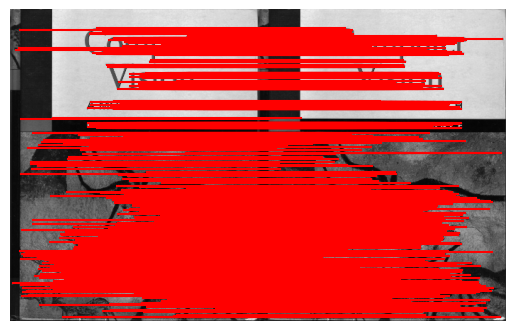

10
20
30


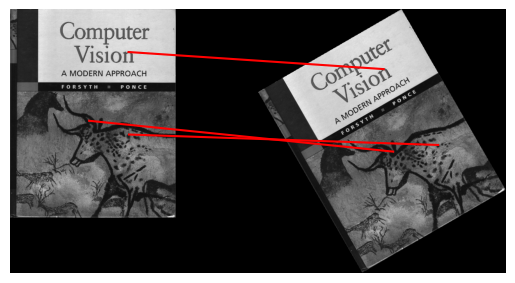

40
50
60
70
80
90


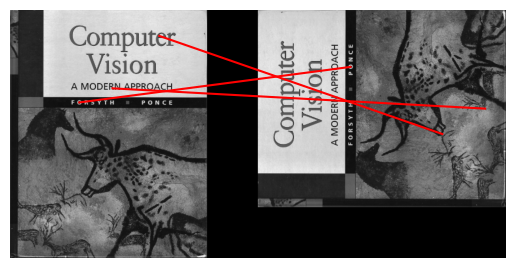

100
110
120
130
140
150
160
170
180
190
200
210
220
230
240
250
260
270
280
290
300
310
320
330
340
350


In [17]:
# defaults are:
# min_deg = 0
# max_deg = 360
# deg_inc = 10
# ratio = 0.7
# sigma = 0.15
# filename = 'cv_cover.jpg'

# Controls the rotation degrees
min_deg = 0
max_deg = 360
deg_inc = 10

# Brief feature descriptor and Fast feature detector paremeters
# (change these if you want to use different values)
ratio = 0.7
sigma = 0.15

# image to rotate and match
# (no need to change this but can if you want to experiment)
filename = 'cv_cover.jpg'

# Call briefRot
briefRot(min_deg, max_deg, deg_inc, ratio, sigma, filename)

Visualize the histogram in the following cell:

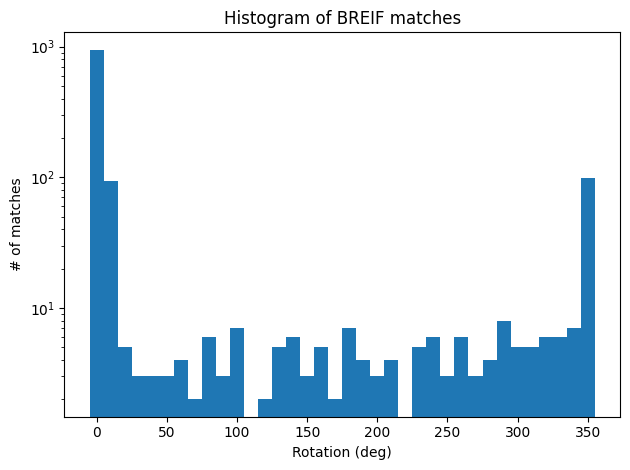

In [18]:
dispBriefRotHist()

Our result verifies the statement claimed by the paper: "BRIEF is not designed to be rotationally invariant." We start with identical descriptors at 0 degree, and numerous matches are found. However, at 30 degrees and 90 degrees, only a few matches are displayed.

The problem is associated with BRIEF. The descriptors are constructed by comparing intensities at fixed positions. When we rotate the image, the contents at the original positions (where we do the comparions) change. Thus, different bits can be produced for the same feature, increasing the Hamming distance and possibly resulting in a false rejection.

The histogram proves my point. The number of matches drops sharply when we move further away from 0 degree, and remains very low among most angles.

### 1.2 Homography Computation

#### 1.2.1 Computing the Homography (15 Points)

Implement the function
```
H2to1 = computeH(x1, x2)
```
that estimates the planar homography from a set of matched points. `x1` and `x2` are N x 2 matrices containing the coordinates (x, y) of point pairs between the two images. `H2to1` should be a 3 x 3 matrix for the best homography from image 2 to image 1 in the least-squares sense. The `numpy.linalg` function `eig()` or `svd()` will be useful to get the eigenvectors.

In [19]:
def computeH(x1, x2):
    """
    Compute the homography between two sets of points

    Input
    -----
    x1, x2: Sets of points

    Returns
    -------
    H2to1: 3x3 homography matrix that best transforms x2 to x1
    """

    if x1.shape != x2.shape:
      raise RuntimeError('number of points do not match')

    # ===== your code here! =====
    N = x1.shape[0]
    if N < 4: raise RuntimeError("at least four pairs are needed")

    A = np.zeros((2*N, 9), dtype=np.float64)
    for i in range(N):
      x, y = x2[i]
      u, v = x1[i]
      A[2*i] = [-x, -y, -1, 0, 0, 0, u*x, u*y, u]
      A[2*i+1] = [0, 0, 0, -x, -y, -1, v*x, v*y, v]
    _, _, VT = np.linalg.svd(A)
    H2to1 = VT[-1].reshape(3, 3)

    # ==== end of code ====

    return H2to1

#### 1.2.2 Homography Normalization (10 points)

Normalization improves numerical stability of the solution and you should always normalize your
coordinate data. Normalization has two steps:
* Translate the mean of the points to the origin.
* Scale the points so that the largest distance to the origin is `sqrt(2)`.

This is a linear transformation and can be written as follows:
$$\tilde{\mathbf{x}}_1 = \mathbf{T}_1 \mathbf{x}_1$$
$$\tilde{\mathbf{x}}_2 = \mathbf{T}_2 \mathbf{x}_2$$
where $\tilde{\mathbf{x}}_1$ and $\tilde{\mathbf{x}}_2$ are the normalized homogeneous coordinates of $\mathbf{x}_1$ and $\mathbf{x}_2$. $\mathbf{T}_1$ and $\mathbf{T}_2$ are 3 x 3 matrices.

The homography $\mathbf{H}$ from $\tilde{\mathbf{x}}_2$ to $\tilde{\mathbf{x}}_1$ computed by `computeH` satisfies
$$\tilde{\mathbf{x}}_1 = \mathbf{H} \tilde{\mathbf{x}}_2$$

By substituting $\tilde{\mathbf{x}}_1$ and $\tilde{\mathbf{x}}_2$ with $\mathbf{T}_1 \mathbf{x}_1$ and $\mathbf{T}_1 \mathbf{x}_1$, we have:
$$\mathbf{T}_1 \mathbf{x}_1 = \mathbf{H} \mathbf{T}_2 \mathbf{x}_2$$
$$\mathbf{x}_1 = \mathbf{T}_1^{-1} \mathbf{H} \mathbf{T}_2 \mathbf{x}_2$$

Implement the function
```
H2to1 = computeH_norm(x1, x2)
```
This function should normalize the coordinates in `x1` and `x2` and call `computeH(x1, x2)` as described above.

In [24]:
def computeH_norm(x1, x2):
    """
    Compute the homography between two sets of points using normalization

    Input
    -----
    x1, x2: Sets of points

    Returns
    -------
    H2to1: 3x3 homography matrix that best transforms x2 to x1
    """

    # ===== your code here! =====

    # Compute the centroid of the points
    centroid1 = np.mean(x1, axis=0)
    centroid2 = np.mean(x2, axis=0)

    # Shift the origin of the points to the centroid
    shifted1 = x1 - centroid1
    shifted2 = x2 - centroid2

    # Normalize the points so that the largest distance from the
    # origin is equal to sqrt(2)
    largest_distance1 = np.max(np.linalg.norm(shifted1, axis=1))
    largest_distance2 = np.max(np.linalg.norm(shifted2, axis=1))
    if largest_distance1 == 0 or largest_distance2 == 0: raise RuntimeError("Division by 0")
    scale1, scale2 = np.sqrt(2)/largest_distance1, np.sqrt(2)/largest_distance2
    normalized1 = shifted1 * scale1
    normalized2 = shifted2 * scale2

    # Similarity transform 1
    T1 = np.array([[scale1, 0, -scale1 * centroid1[0]],
            [0, scale1, -scale1 * centroid1[1]],
            [0, 0, 1]])

    # Similarity transform 2
    T2 = np.array([[scale2, 0, -scale2 * centroid2[0]],
            [0, scale2, -scale2 * centroid2[1]],
            [0, 0, 1]])

    # Compute homography
    H = computeH(normalized1, normalized2)

    # Denormalization
    H2to1 = np.linalg.inv(T1) @ H @ T2

    # ==== end of code ====

    return H2to1

#### 1.2.3 Implement RANSAC (25 points):

The RANSAC algorithm can generally fit any model to noisy data. You will implement it for (planar) homographies between images. Remember that 4 point-pairs are required at a minimum to compute a homography.

Write a function
```
bestH2to1, best_inliers = computeH_ransac(locs1, locs2, max_iters, inlier_tol)
```
where `locs1` and `locs2` are N x 2 matrices containing the matched points. `max_iters` is the number of iterations to run RANSAC for, and `inlier_tol` is the tolerance value for considering a point to be an inlier. `bestH2to1` should be the homography `H` with most inliers found during RANSAC. `H` will be a homography such that if $\mathbf{x}_2$ is a point in `locs2` and $\mathbf{x}_1$ is a corresponding point in `locs1`, then $\mathbf{x}_1 = \mathbf{H} \mathbf{x}_2$. `inliers` is a vector of length N with a 1 at those matches that are part of the consensus set, and 0 elsewhere. Use `computeH_norm` to compute the homography.

In [25]:
def computeH_ransac(locs1, locs2, max_iters, inlier_tol):
  """
  Estimate the homography between two sets of points using ransac

  Input
  -----
  locs1, locs2: Lists of points
  max_iters: the number of iterations to run RANSAC for
  inlier_tol: the tolerance value for considering a point to be an inlier

  Returns
  -------
  bestH2to1: 3x3 homography matrix that best transforms locs2 to locs1
  inliers: indices of RANSAC inliers

  """

  # ===== your code here! =====

  # Compute the best fitting homography using RANSAC
  # given a list of matching points locs1 and loc2
  locs1 = np.asarray(locs1, dtype=np.float64)
  locs2 = np.asarray(locs2, dtype=np.float64)

  if locs1.shape != locs2.shape:
    raise RuntimeError('number of points do not match')

  N = locs1.shape[0]
  if N < 4: raise RuntimeError("at least four pairs are needed")

  points2 = np.hstack((locs2, np.ones((N, 1))))
  bestH2to1 = None
  best_inliers = None
  best_count = 0

  def find_inliers(H):
    proj = (H @ points2.T).T

    # Avoid division by zero
    valid = np.abs(proj[:, 2]) > 1e-10
    errors = np.full(N, np.inf)

    predicted = proj[valid, :2] / proj[valid, 2:3]
    errors[valid] = np.linalg.norm(predicted - locs1[valid], axis=1)
    return errors < inlier_tol

  for _ in range(max_iters):
    indices = np.random.choice(N, size=4, replace=False)
    sample1 = locs1[indices]
    sample2 = locs2[indices]

    valid_sample = True
    for sample in (sample1, sample2):
      for j in range(4):
        three = np.delete(sample, j, axis=0)
        matrix = np.hstack((three, np.ones((3, 1))))
        if np.linalg.matrix_rank(matrix) < 3: valid_sample = False

    if not valid_sample:
      continue

    try:
      H = computeH_norm(sample1, sample2)
    except (np.linalg.LinAlgError, RuntimeError):
      continue

    if not np.all(np.isfinite(H)):
      continue

    inliers = find_inliers(H)
    count = np.sum(inliers)

    if count > best_count:
      best_count = count
      bestH2to1 = H
      best_inliers = inliers.astype(int)

  if best_count < 4: raise RuntimeError("unable to find a valid homography")

  H = computeH_norm(locs1[best_inliers.astype(bool)], locs2[best_inliers.astype(bool)])
  inliers = find_inliers(H)

  if np.sum(inliers) >= best_count:
    bestH2to1 = H
    best_inliers = inliers.astype(int)

  # ==== end of code ====

  return bestH2to1, best_inliers

#### 1.2.4 Automated Homography Estimation and Warping (10 points)

Implement the function
```
composite_img = compositeH(H2to1, template, img)
```
that composes a warped template image on top of another image. You may want to use the OpenCV function `cv2.warpPerspective`.

In [26]:
def compositeH(H2to1, template, img):
    """
    Returns the composite image.

    Input
    -----
    H2to1: Homography from image to template
    template: template image to be warped
    img: background image

    Returns
    -------
    composite_img: Composite image

    """

    # ===== your code here! =====
    # Create a composite image after warping the template image on top
    # of the image using the homography
    H = np.linalg.inv(H2to1)
    h, w = img.shape[:2]

    warped = cv2.warpPerspective(template, H, (w, h))

    mask = np.ones(template.shape[:2], dtype=np.uint8)
    mask = cv2.warpPerspective(mask, H, (w, h), flags=cv2.INTER_NEAREST).astype(bool)

    composite_img = img.copy()
    composite_img[mask] = warped[mask]

    # ==== end of code ====

    return composite_img

Implement the function
```
warpImage(ratio, sigma, max_iters, inlier_tol)
```
that
* Reads *cv_cover.jpg*, *cv_desk.png*, and *hp_cover.jpg*.
* Computes a homography automatically using `matchPics()` and `computeH_ransac()` (remember
to adjust for the size different between *cv_cover.jpg* and *hp_cover.jpg*).
* Uses `compositeImage()` to compose this warped image with the desk image as in Figure 2 (see below).

In [39]:
def warpImage(ratio, sigma, max_iters, inlier_tol):
    """
    Warps hp_cover.jpg onto the book cover in cv_desk.png.

    Input
    -----
    ratio: ratio for BRIEF feature descriptor
    sigma: threshold for corner detection using FAST feature detector
    max_iters: the number of iterations to run RANSAC for
    inlier_tol: the tolerance value for considering a point to be an inlier

    """

    hp_cover = skimage.io.imread(os.path.join(DATA_DIR, 'hp_cover.jpg'))
    cv_cover = skimage.io.imread(os.path.join(DATA_DIR, 'cv_cover.jpg'))
    cv_desk = skimage.io.imread(os.path.join(DATA_DIR, 'cv_desk.png'))
    cv_desk = cv_desk[:, :, :3]

    # ===== your code here! =====

    # Match features between cv_desk and cv_cover using matchPics\
    matches, locs1, locs2 = matchPics(cv_desk, cv_cover, ratio, sigma)
    desk_points = locs1[matches[:, 0]][:, ::-1].astype(np.float64)
    cover_points = locs2[matches[:, 1]][:, ::-1].astype(np.float64)

    # Scale matched pixels in cv_cover to size of hp_cover
    h, w = cv_cover.shape[:2]
    hp_h, hp_w = hp_cover.shape[:2]
    cover_points[:, 0] *= hp_w / w
    cover_points[:, 1] *= hp_h / h

    # Get homography by RANSAC using computeH_ransac
    H, _ = computeH_ransac(cover_points, desk_points, max_iters, inlier_tol)

    # Overlay using compositeH to return composite_img
    composite_img = compositeH(H, hp_cover, cv_desk)

    # ==== end of code ====

    plt.imshow(composite_img)
    plt.show()

![Figure 2](http://16385.courses.cs.cmu.edu/fall2026/assets/assignments/hw2/fig2.png)
*Figure 2:* An ordinary textbook (left). Harry-Potterized book (right).

The example shown in Figure 2 is with `ratio = 0.7`, `sigma = 0.15`, `max_iters = 600`, and `inlier_tol = 1.0`.

/tmp/ipykernel_1104/3128789144.py:60: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  return 1 if img[int(center[0]+row1)][int(center[1]+col1)] < img[int(center[0]+row2)][int(center[1]+col2)] else 0


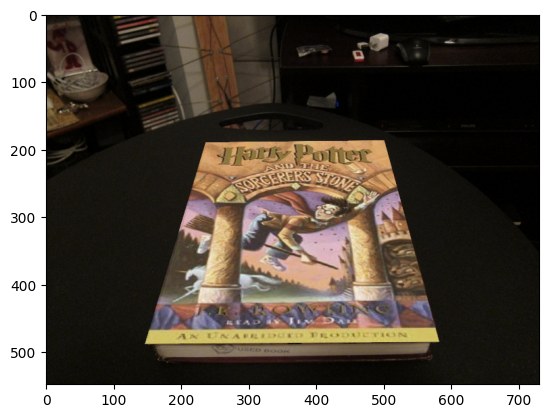

In [43]:
# defaults are:
# ratio = 0.7
# sigma = 0.15
# max_iters = 600
# inlier_tol = 1.0

# (no need to change this but can if you want to experiment)
ratio = 0.7
sigma = 0.15
max_iters = 600
inlier_tol = 1.0

warpImage(ratio, sigma, max_iters, inlier_tol)


#### 1.2.5 RANSAC Parameter Tuning (10 points)

Just like how we tune parameters for feature matching, there are two tunable parameters in RANSAC
as well: `max_iters` and `inlier_tol`. Conduct a small sensitivity analysis by calling `warpImage()` with
various `max_iters` and `inlier_tol` values. Plot the result images and explain the effect of these two
parameters respectively.

In [55]:
# ===== your code here! =====
# Experiment with different max_iters and inlier_tol values.
# Include the result images in the write-up.
ratio = 0.7
sigma = 0.15

for max_iters in [1, 5, 20, 600]:
    print("\n")
    np.random.seed(0)
    print(f"max_iters = {max_iters}")
    plt.figure()
    warpImage(ratio, sigma, max_iters, inlier_tol=1.0)

print("\n\n\n")

for inlier_tol in [0.3, 1.0, 50.0, 100.0]:
    print("\n")
    np.random.seed(0)
    print(f"inlier_tol = {inlier_tol}")
    plt.figure()
    warpImage(ratio, sigma, max_iters=600, inlier_tol=inlier_tol)

# ==== end of code ====

Output hidden; open in https://colab.research.google.com to view.

Effect of max_iters: At very small max_iters(for example, 1), we see the overlay is severely distorted. It is improved with increased iterations, and becomes well-aligned after 20 iterations. Increasing max_iters increases the chance of sampling four correct macthes and thus finding a reliable homography.Once this is satisfied, increaing iterations even further offers very little improvement (not even visible, in my opinion).

Effect of inlier_tol: Low tolerance (such as 0.3 and 1.0) gives better alignment. Distortion becomes increasingly severe as we increase the tolerance. This is because higher inlier_tol permits matches with larger projection errors to count as inliers. Thus, we have a higher chance to admit false matches. In contrast, a small tolerance rejects more strictly, but could also reject correct matches.

---
## Section 2: Create a Simple Panorama

### 2.1 Create a panorama (10 points)

Implement the function
```
panorama_im = createPanorama(left_im, right_im, ratio, sigma, max_iters, inlier_tol)
```
which computes the homography between two images separated by a pure rotation and stitches them together. Then, take two pictures with your own camera, separated by a pure rotation as best as possible, call `createPanorama()`, and visualize the results. Be sure that objects in the images are far enough away so that there are no parallax effects. You can use the python module `cpselect` to select matching points on each image or some automatic method. We have provided two images for you to get started (*data/pano_left.jpg* and *data/pano_right.jpg*). Please use your own images when submitting this project. Include original images and the final panorama result image in the write-up. See Figure 3 below for an example.

![Figure 3](http://16385.courses.cs.cmu.edu/fall2026/assets/assignments/hw2/fig3.png)
*Figure 3:* Original Image 1 (top left). Original Image 2 (top right). Panorama (bottom).

In [48]:
def createPanorama(left_im, right_im, ratio, sigma, max_iters, inlier_tol):
    """
    Create a panorama augmented reality application by computing a homography
    and stitching together a left and right image.

    Input
    -----
    left_im: left image
    right_im: right image
    ratio: ratio for BRIEF feature descriptor
    sigma: threshold for corner detection using FAST feature detector
    max_iters: the number of iterations to run RANSAC for
    inlier_tol: the tolerance value for considering a point to be an inlier

    Returns
    -------
    panorama_im: Stitched together panorama

    """

    # ===== your code here! =====
    # match features between images
    matches, locs1, locs2 = matchPics(left_im, right_im, ratio, sigma)
    points1 = locs1[matches[:, 0]][:, ::-1]
    points2 = locs2[matches[:, 1]][:, ::-1]

    # Get homography by RANSAC using computeH_ransac
    H, _ = computeH_ransac(points1, points2, max_iters, inlier_tol)
    h1, w1 = left_im.shape[:2]
    h2, w2 = right_im.shape[:2]
    corners1 = np.array([[0, 0], [w1 - 1, 0], [w1 - 1, h1 - 1], [0, h1 - 1]], dtype=np.float64)
    corners2 = np.array([[0, 0], [w2 - 1, 0], [w2 - 1, h2 - 1], [0, h2 - 1]], dtype=np.float64)

    warped_corners = cv2.perspectiveTransform(corners2.reshape(-1, 1, 2), H).reshape(-1, 2)
    corners = np.vstack((corners1, warped_corners))
    x_min, y_min = np.floor(corners.min(axis=0)).astype(int)    # so buggy...
    x_max, y_max = np.ceil(corners.max(axis=0)).astype(int)

    T = np.array([[1, 0, -x_min], [0, 1, -y_min], [0, 0, 1]], dtype=np.float64)
    panorama_im = cv2.warpPerspective(right_im, T @ H,(int(x_max - x_min + 1), int(y_max - y_min + 1)))

    x, y = -x_min, -y_min
    panorama_im[y:y+h1, x:x+w1] = left_im

    # ==== end of code ====

    return panorama_im.astype(np.uint8)

#### Visualize Panorama

Make sure to use **your own images** and **include them as well as the result** in the report.

/tmp/ipykernel_1104/3128789144.py:60: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  return 1 if img[int(center[0]+row1)][int(center[1]+col1)] < img[int(center[0]+row2)][int(center[1]+col2)] else 0


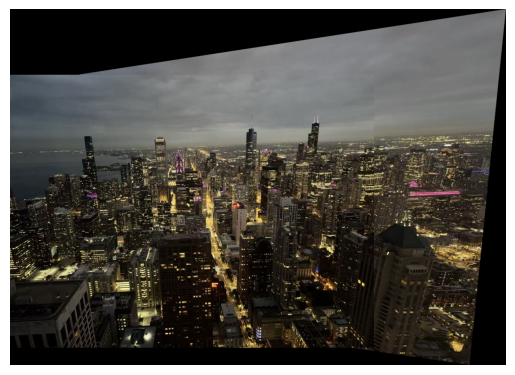

In [53]:
left_im_path = os.path.join(DATA_DIR, 'chicago_left.jpg')
left_im = skimage.io.imread(left_im_path)
right_im_path = os.path.join(DATA_DIR, 'chicago_right.jpg')
right_im = skimage.io.imread(right_im_path)

# Feel free to adjust as needed
ratio = 0.7
sigma = 0.15
max_iters = 600
inlier_tol = 1.0

panorama_im = createPanorama(left_im, right_im, ratio, sigma, max_iters, inlier_tol)

plt.imshow(panorama_im)
plt.axis('off')
plt.show()

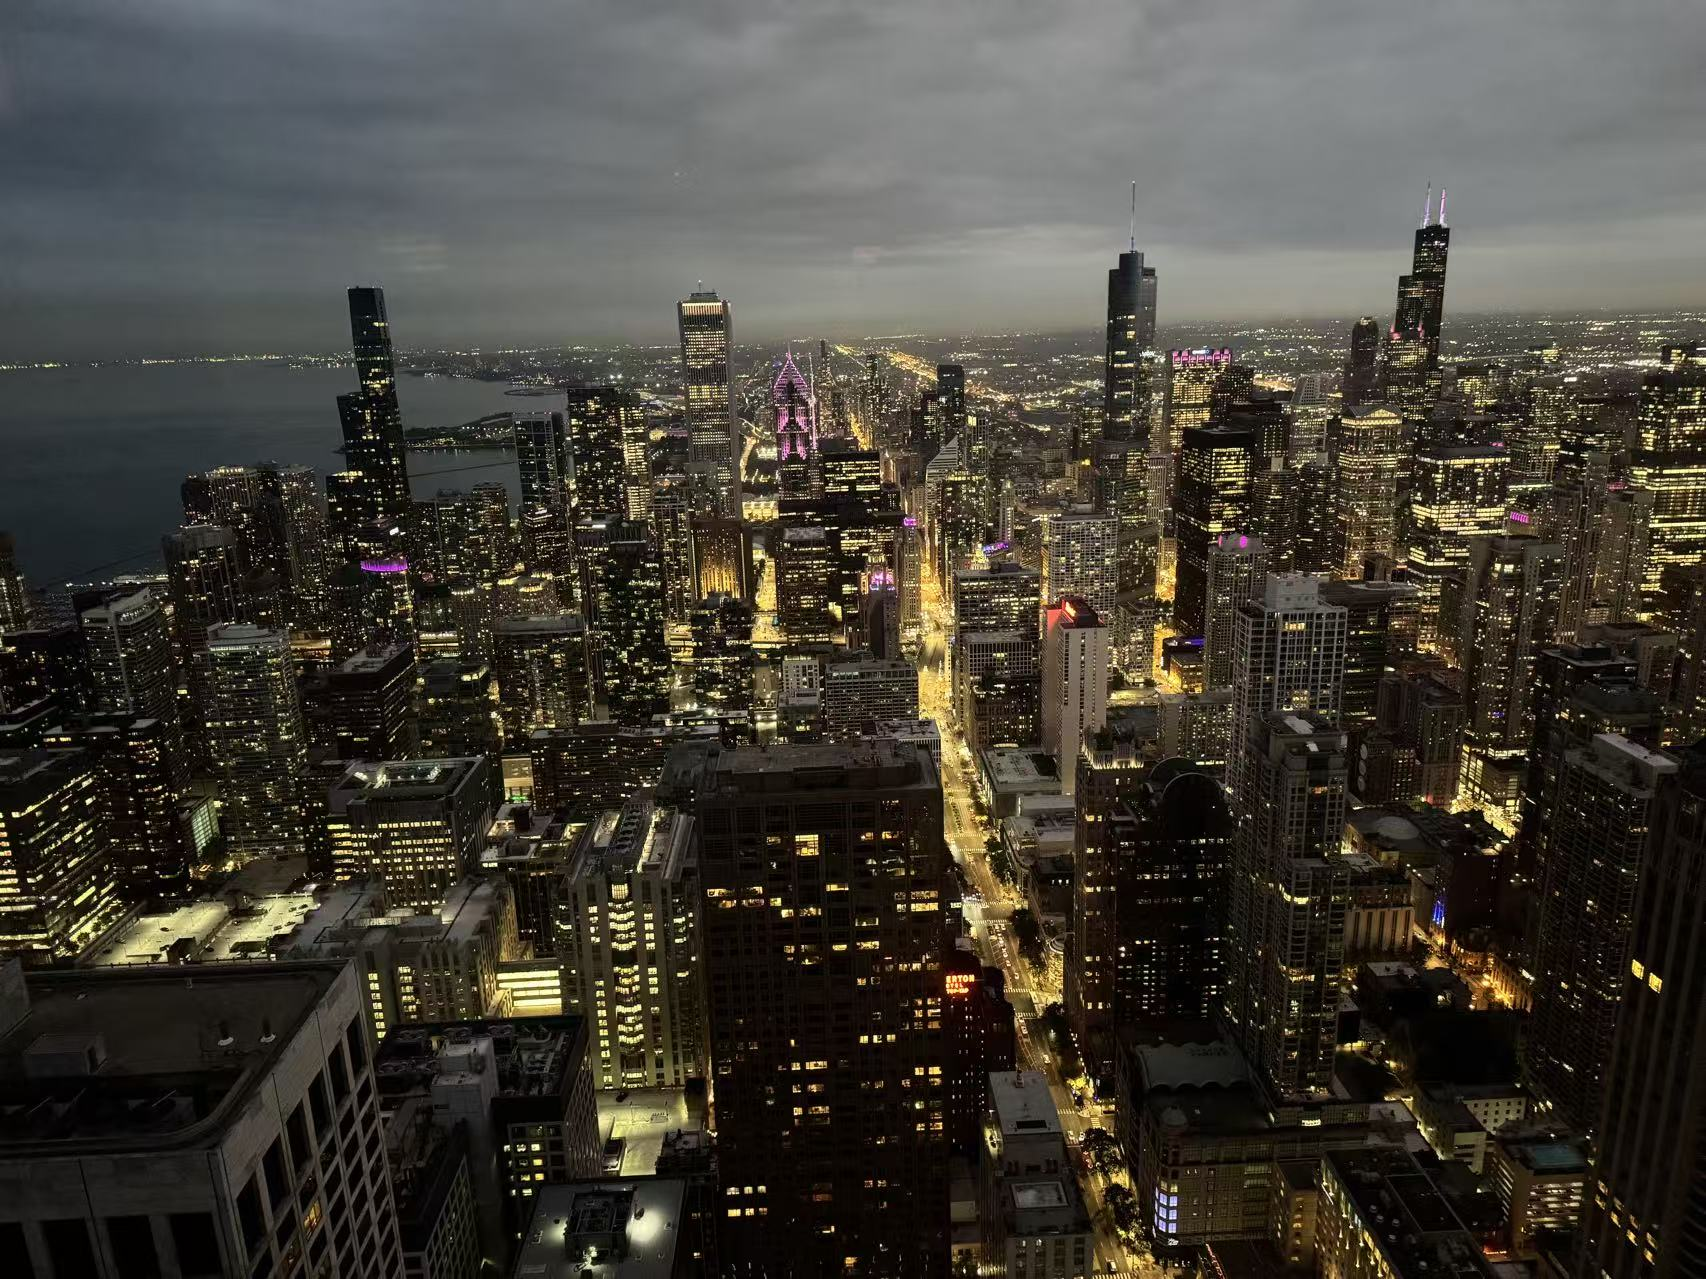

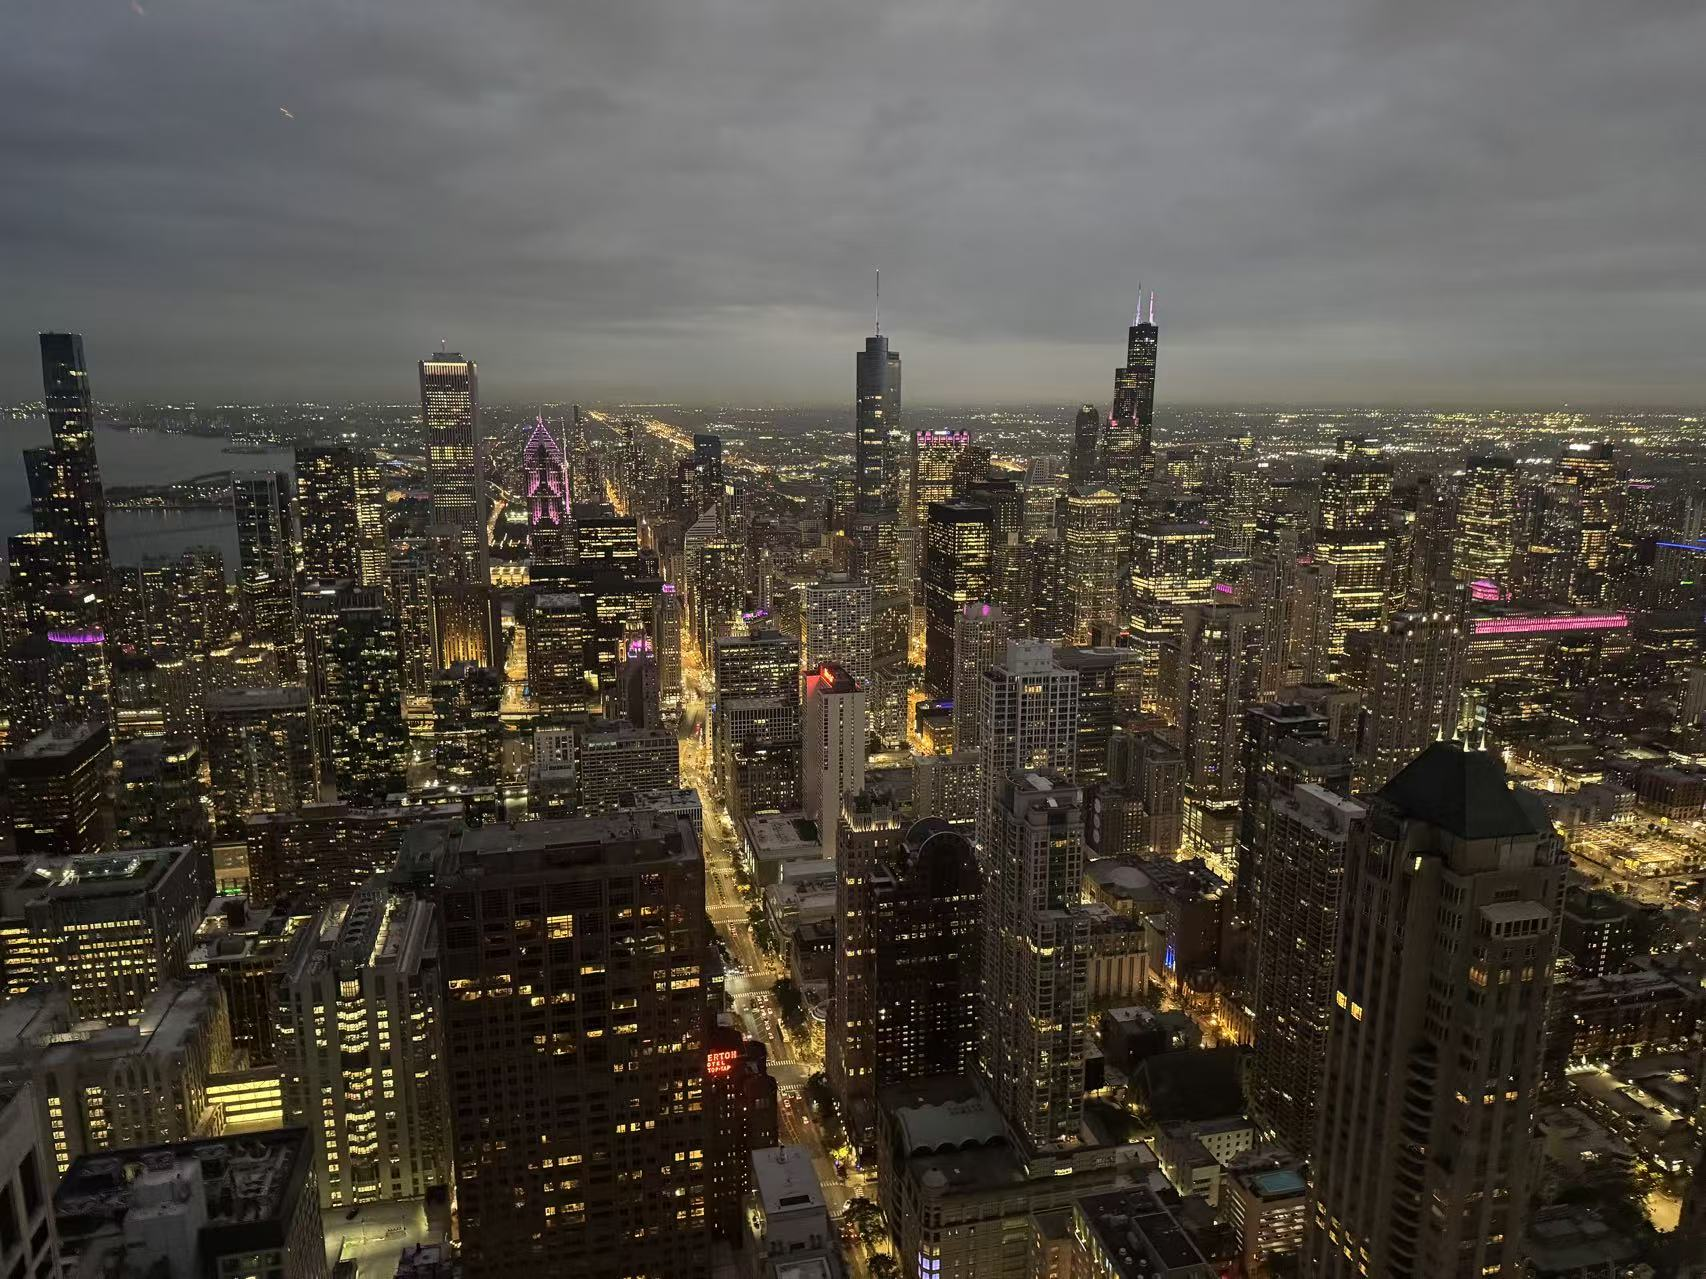

### FAQs

1. In `matchPics`, `locs` stands for pixel locations. `locs1` and `locs2` can have different sizes, since matches gives the mapping between the two for corresponding matches. We use `skimage.feature.match` descriptors (API) to calculate the correspondences.

2. Normalized homography: The function `computeH_norm` should return the homography `H` between unnormalized coordinates and not the normalized homography `H_norm`.

3. The `locs` produced by `matchPics` are in the form of [row, col], which is (y,x) in coordinates. Therefore, you should first swap the columns returned by matchPics and then feed into Homography estimation.

4. Note that the third output `np.linalg.svd` is `vh` when computing homographies.

5. When debugging homographies, it is helpful to visualize the matches, and checking homographies with the same image. If there is not enough matches, try tuning the parameters.

### Generate your PDF

Run this cell LAST to generate your PDF. You will be prompted to grant permission. Please click "Select all" and then "Continue." This allows Colab to access the notebook contents to create the PDF (it does not access anything outside your notebook). It may take ~1 minute to complete-please be patient and do not rerun the cell. The PDF (including both your code and its output) will automatically download to your Downloads folder.

### Optional PDF export
Use Jupyter's **Save and Export Notebook As** menu, or Colab's **File → Print**. PDF export is separate from running the project and requires no Drive authorization.
